**Real-world question:** How do image transforms help us inspect a photo or a
scientific data matrix, and what information can they hide?

**Deliverables:** a before/after image comparison, a raw/smoothed CO₂ heatmap,
and a short explanation of the trade-off between visual clarity and data fidelity.

We use the bundled 512 × 512 grayscale photograph and the **same complete
weekly CO₂ dataset** from Activities 1–3A.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when you launch Jupyter from the repository root or notebooks/ folder.
def data_path(filename):
    # Search for the data folder from the current
    # working directory up to the repository root.
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find {filename}. "
        f"Current directory: {Path.cwd()}"
    )

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 105})

from PIL import Image
from scipy import ndimage

## Step 1 — Read the supplied image as a numeric array
    The image is stored as 8-bit grayscale: pixel values from **0** to **255**.
    The `PIL` import is used only to load the PNG; the transforms use SciPy.

Shape: (512, 512) | dtype: uint8 | range: 0 to 255


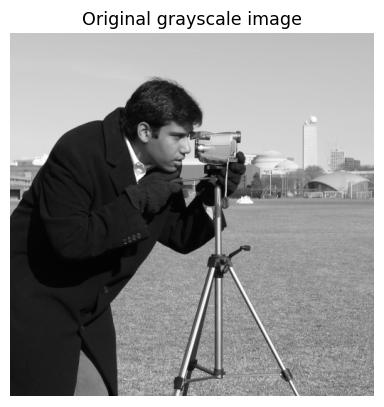

In [3]:
image = np.asarray(Image.open(data_path('Camera_Practice_Image.png')).convert('L'))
assert image.shape == (512, 512)
print('Shape:', image.shape, '| dtype:', image.dtype,
      '| range:', image.min(), 'to', image.max())
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Original grayscale image')
plt.axis('off')
plt.show()

## Step 2 — Crop, rotate, blur, and sharpen
    Rotation can discard corners when `reshape=False`. Gaussian smoothing
    removes local variation but can erase edges. Sharpening increases contrast
    around edges and can amplify noise.

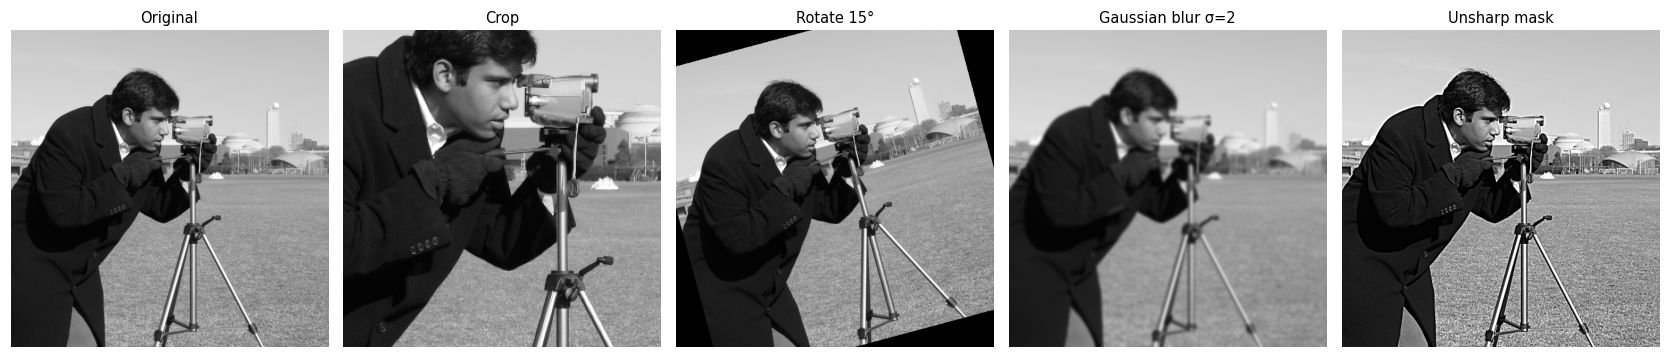

In [4]:
image_float = image.astype(float)
cropped = image[100:380, 100:380]
rotated = ndimage.rotate(image_float, 15, reshape=False)
blurred = ndimage.gaussian_filter(image_float, sigma=2)
sharpened = np.clip(image_float + 1.2 * (image_float - blurred), 0, 255)

panels = [('Original', image_float), ('Crop', cropped),
          ('Rotate 15°', rotated), ('Gaussian blur σ=2', blurred),
          ('Unsharp mask', sharpened)]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (title, pixels) in zip(axes, panels):
    ax.imshow(pixels, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Step 3 — Apply the same idea to a scientific data matrix
    The **43 complete years × 12 months** CO₂ matrix is a 2D array.
    We subtract the illustrative 315 ppm baseline, then smooth the matrix.

    **Warning:** Smoothing changes numeric values. Use the **raw observations**
    for quantitative conclusions; the filtered heatmap is for visual exploration.

In [6]:
df = (pd.read_csv(data_path('MaunaLoa_CO2_Full.csv'), parse_dates=['date'])
        .set_index('date').sort_index())
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == 2284, 'Please use the supplied full historical dataset.'
assert int(df['co2_ppm'].isna().sum()) == 59
print('Rows:', len(df), '| Missing:', df['co2_ppm'].isna().sum())
print('Period:', df.index.min().date(), 'to', df.index.max().date())
display(df.head())

Rows: 2284 | Missing: 59
Period: 1958-03-29 to 2001-12-29


,co2_ppm
date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


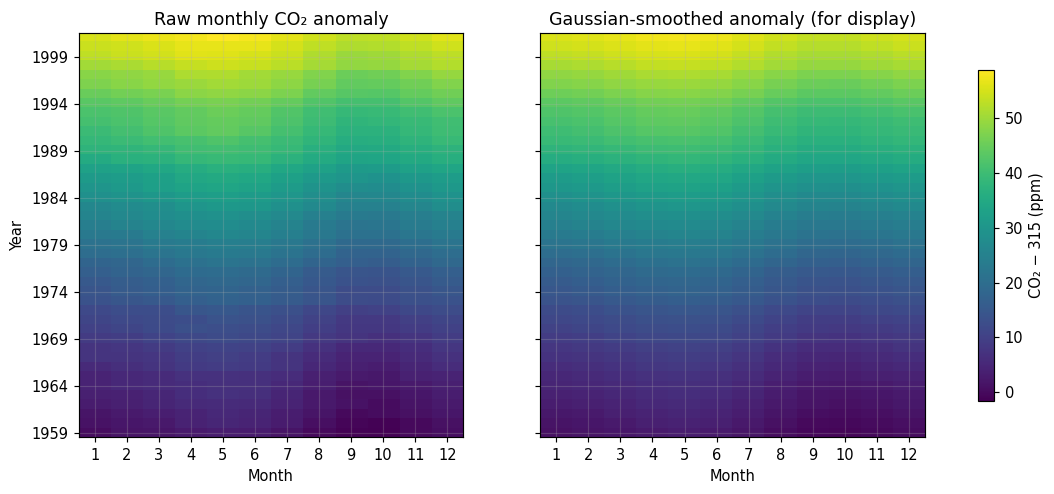

In [7]:
filled = df.co2_ppm.interpolate(method='time', limit_area='inside')
monthly = filled.resample('MS').mean()
year_month = (monthly.to_frame('co2_ppm')
              .assign(year=lambda d: d.index.year,
                      month=lambda d: d.index.month)
              .pivot(index='year', columns='month', values='co2_ppm')
              .dropna())
assert year_month.shape == (43, 12)

raw_anomaly = year_month.to_numpy() - 315.0
smoothed_anomaly = ndimage.gaussian_filter(raw_anomaly,
                                            sigma=(0.7, 1.0), mode='reflect')
vmin, vmax = raw_anomaly.min(), raw_anomaly.max()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, matrix, title in zip(
        axes, [raw_anomaly, smoothed_anomaly],
        ['Raw monthly CO₂ anomaly', 'Gaussian-smoothed anomaly (for display)']):
    im = ax.imshow(matrix, aspect='auto', origin='lower', cmap='viridis',
                   vmin=vmin, vmax=vmax)
    ax.set(title=title, xlabel='Month')
    ax.set_xticks(range(12), labels=range(1, 13))
axes[0].set_ylabel('Year')
axes[0].set_yticks(range(0, len(year_month), 5),
                   labels=year_month.index[::5].tolist())
fig.colorbar(im, ax=axes.ravel().tolist(), label='CO₂ − 315 (ppm)', shrink=0.82)
plt.show()

## Step 4 — Measure what smoothing changed
    Even if a heatmap looks clearer, the smoothed matrix is **not identical**
    to the original values. Calculate the average and maximum absolute change.

In [8]:
difference = smoothed_anomaly - raw_anomaly
print('Mean absolute change (ppm):', round(np.mean(np.abs(difference)), 3))
print('Maximum absolute change (ppm):', round(np.max(np.abs(difference)), 3))
print('Raw matrix shape:', raw_anomaly.shape)

Mean absolute change (ppm): 0.377
Maximum absolute change (ppm): 1.634
Raw matrix shape: (43, 12)


## Your investigation — interpret the transformations
    **A.** Which transform best helps you inspect **large-scale structure**?
    Which preserves fine detail? Which may lose information?

    **B.** Compare `sigma=1` and `sigma=4` on the photograph. Explain how the
    amount of smoothing changes the result.

    **C.** Explain why the smoothed CO₂ heatmap should **not** replace the raw
    matrix for numerical reporting.

    **Extension:** Use `ndimage.sobel` to find edges in the photograph.
    What is detected? Would this edge detector be meaningful on the CO₂ matrix?

In [ ]:
# YOUR TURN
# 1. Change sigma in ndimage.gaussian_filter(image_float, sigma=...).
# 2. Compute horizontal and vertical Sobel responses.
# 3. Plot the gradient magnitude as an image.

### Reflection checklist
    - [ ] I treated both the photograph and the data table as arrays.
    - [ ] I used the same colour scale in the raw/smoothed heatmaps.
    - [ ] I measured how filtering changed values.
    - [ ] I explained that visual processing is not a substitute for raw evidence.